# 01 - Thống kê mô tả trên dữ liệu COVID (Our World in Data)

Mục tiêu: tính mean, median, mode, variance, standard deviation, range, percentile, quartile, IQR cho `new_cases` bằng numpy và scipy.stats (bài mẫu 1.1.2, bài toán 1, nhiệm vụ 1).

## 1. Load data và kiểm tra nhanh

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
FIG_DIR = ROOT / 'figures'
REPORT_DIR = ROOT / 'reports'
FIG_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


def doc_csv(path, **kwargs):
    return pd.read_csv(path, sep=None, engine='python', **kwargs)


def can_file(*names):
    for name in names:
        if (DATA_DIR / name).exists():
            return DATA_DIR / name
    raise FileNotFoundError(f'Không thấy {names} trong {DATA_DIR}. Xem data/README.txt để biết cách tải.')


def mo_ta_thong_ke(frame):
    rows = {}
    for col in frame.select_dtypes(include=np.number).columns:
        s = frame[col].dropna()
        if s.empty:
            continue
        q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
        iqr = q3 - q1
        rows[col] = {
            'count': s.size, 'mean': s.mean(), 'median': s.median(), 'mode': s.mode().iloc[0],
            'variance': s.var(), 'std': s.std(), 'min': s.min(), 'max': s.max(), 'range': s.max() - s.min(),
            'P60': np.percentile(s, 60), 'Q1': q1, 'Q2': q2, 'Q3': q3, 'IQR': iqr,
            'skew': s.skew(), 'kurtosis': s.kurt(),
            'so_outlier_iqr': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        }
    return pd.DataFrame(rows).T


def kiem_tra_chat_luong(frame, ten):
    print(f'=== {ten} ===')
    print('Shape:', frame.shape)
    print('Số dòng trùng lặp:', int(frame.duplicated().sum()))
    thieu = frame.isna().sum()
    print('Giá trị thiếu theo cột:')
    print(thieu[thieu > 0] if thieu.sum() else '  Không có giá trị thiếu')


def luoi(cols, ve, ncols=4, size=(4.5, 3.2)):
    cols = list(cols)
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        ve(ax, col)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    return fig


def luu_hinh(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def cap_nhat_summary(notebook, dataset, frame):
    tk = mo_ta_thong_ke(frame)
    row = {
        'notebook': notebook, 'dataset': dataset, 'rows': len(frame), 'cols': frame.shape[1],
        'numeric_cols': len(frame.select_dtypes(include=np.number).columns),
        'categorical_cols': len(frame.select_dtypes(exclude=np.number).columns),
        'missing_cells': int(frame.isna().sum().sum()), 'duplicate_rows': int(frame.duplicated().sum()),
        'outlier_cells_iqr': int(tk['so_outlier_iqr'].sum()) if len(tk) else 0,
    }
    path = FIG_DIR / 'results_summary.csv'
    old = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=list(row))
    old = old[old['notebook'] != notebook]
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print('Đã cập nhật:', path.name)

path = can_file('covid-data.csv', 'owid-covid-data.csv')
cols = ['iso_code', 'continent', 'location', 'date', 'total_cases', 'new_cases']
covid = pd.read_csv(path, usecols=cols, parse_dates=['date'])
kiem_tra_chat_luong(covid, 'COVID')
display(covid.head())
display(covid.dtypes.to_frame('dtype').T)

=== COVID ===
Shape: (429435, 6)
Số dòng trùng lặp: 0
Giá trị thiếu theo cột:
continent      26525
total_cases    17631
new_cases      19276
dtype: int64


,iso_code,continent,location,date,total_cases,new_cases
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0


,iso_code,continent,location,date,total_cases,new_cases
dtype,object,object,object,datetime64[ns],float64,float64


## 2. Thống kê mô tả cho `new_cases`

Cột `new_cases` có giá trị thiếu nên `np.mean` trên dữ liệu gốc trả về `nan`; phải bỏ NaN trước khi tính. `np.var`/`np.std` mặc định chia cho N (ddof=0), còn pandas chia cho N-1.

In [2]:
raw = covid['new_cases']
print('np.mean trên dữ liệu còn NaN ->', np.mean(raw))
x = raw.dropna()
print(f'Số dòng dùng để tính: {len(x)} / {len(raw)}')
print('Số dòng new_cases âm (OWID hiệu chỉnh số liệu):', int((x < 0).sum()))

mode_result = stats.mode(x)
ket_qua = {
    'mean': np.mean(x),
    'median': np.median(x),
    'mode': np.atleast_1d(mode_result.mode)[0],
    'variance (ddof=0)': np.var(x),
    'std (ddof=0)': np.std(x),
    'min': np.min(x),
    'max': np.max(x),
    'range': np.max(x) - np.min(x),
    'percentile 60': np.percentile(x, 60),
    'Q1 (25%)': np.quantile(x, 0.25),
    'Q3 (75%)': np.quantile(x, 0.75),
    'IQR': stats.iqr(x),
}
ket_qua_df = pd.Series(ket_qua, name='new_cases').round(2).to_frame()
display(ket_qua_df)
ket_qua_df.to_csv(FIG_DIR / '01_covid_new_cases_stats.csv')
print('Mean > median ->', bool(ket_qua['mean'] > ket_qua['median']), '(phân bố lệch phải)')

np.mean trên dữ liệu còn NaN -> 8017.359933586731
Số dòng dùng để tính: 410159 / 429435
Số dòng new_cases âm (OWID hiệu chỉnh số liệu): 0


,new_cases
mean,8.017360e+03
median,0.000000e+00
mode,0.000000e+00
variance (ddof=0),5.274582e+10
std (ddof=0),2.296646e+05
min,0.000000e+00
max,4.423623e+07
range,4.423623e+07
percentile 60,0.000000e+00
Q1 (25%),0.000000e+00


Mean > median -> True (phân bố lệch phải)


## 3. So sánh theo châu lục và trực quan hóa

,count,mean,median,std,max
continent,,,,,
Africa,95411,137.8,0.0,2033.3,162987.0
Asia,78675,3833.0,0.0,181035.1,40475477.0
Europe,84190,3004.1,0.0,35559.8,2417043.0
North America,68188,1825.7,0.0,49486.4,5650933.0
Oceania,40172,373.5,0.0,8810.4,588813.0
South America,23435,2936.2,0.0,28665.7,1283024.0


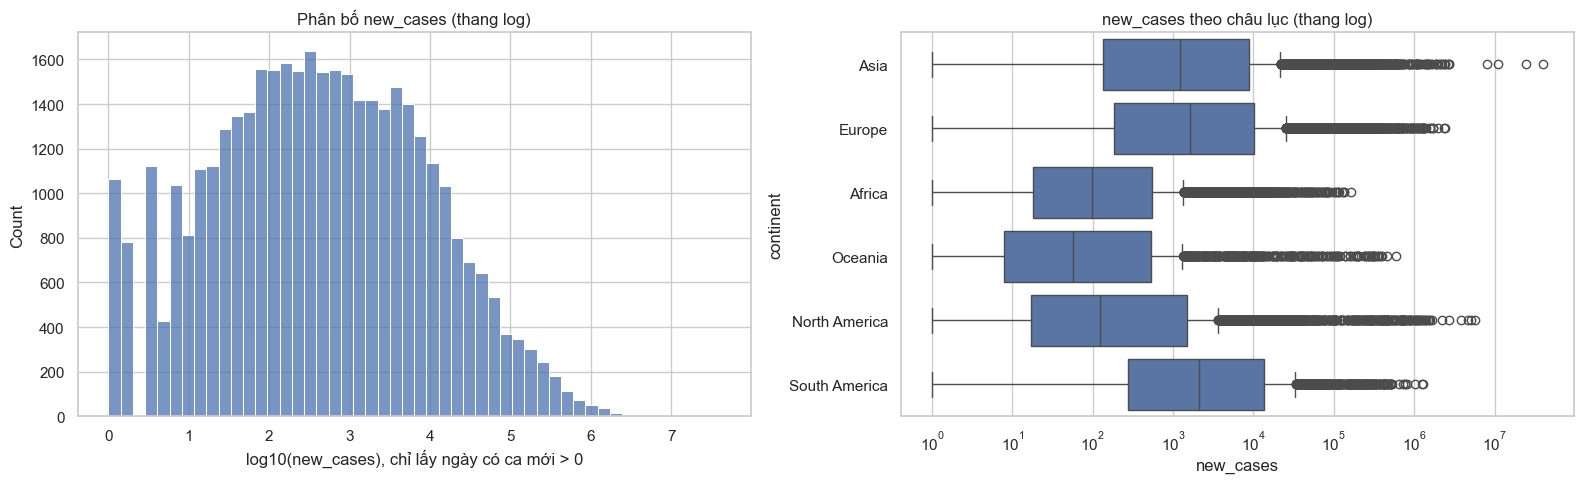

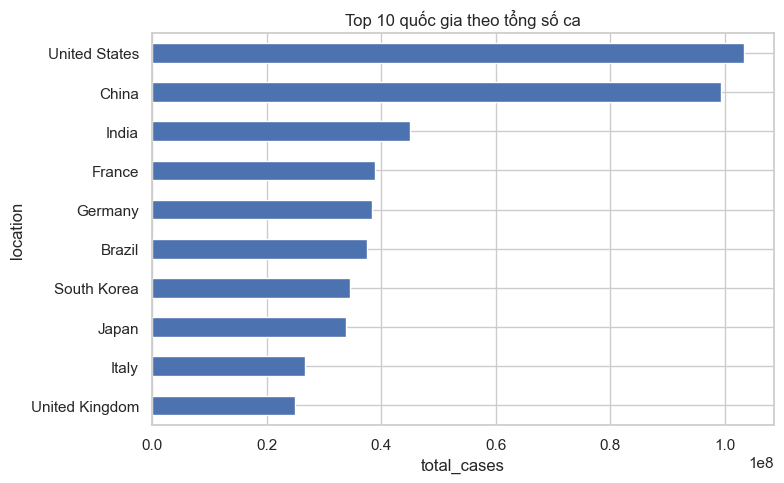

Đã cập nhật: results_summary.csv


In [3]:
countries = covid.dropna(subset=['continent'])
theo_chau_luc = countries.groupby('continent')['new_cases'].agg(['count', 'mean', 'median', 'std', 'max']).round(1)
display(theo_chau_luc)

pos = countries[countries['new_cases'] > 0]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(np.log10(pos['new_cases']), bins=50, ax=axes[0])
axes[0].set_xlabel('log10(new_cases), chỉ lấy ngày có ca mới > 0')
axes[0].set_title('Phân bố new_cases (thang log)')
sns.boxplot(data=pos, x='new_cases', y='continent', ax=axes[1])
axes[1].set_xscale('log')
axes[1].set_title('new_cases theo châu lục (thang log)')
luu_hinh('01_covid_new_cases_distribution')

top10 = countries.groupby('location')['total_cases'].max().nlargest(10).sort_values()
plt.figure(figsize=(8, 5))
top10.plot.barh()
plt.xlabel('total_cases'); plt.title('Top 10 quốc gia theo tổng số ca')
luu_hinh('01_covid_top10_total_cases')
cap_nhat_summary('01_covid_descriptive', 'covid-data.csv', covid)

## 4. Nhận xét

`new_cases` lệch phải rất mạnh (mean lớn hơn median nhiều, max rất xa Q3) nên với dữ liệu này trung vị mô tả "ngày điển hình" tốt hơn trung bình. Dữ liệu có NaN và một số giá trị âm do OWID điều chỉnh số liệu; các dòng tổng hợp (`continent` rỗng) được loại khi so sánh giữa các châu lục để tránh đếm trùng.